# 📝 Actividad de Evaluación: Análisis Exploratorio de Portafolios (10%)

**Instrucciones:**
1. Resuelve cada uno de los puntos solicitados utilizando código de Python limpio y ordenado.
2. No olvides acompañar cada visualización con su respectiva **interpretación analítica** (recuerda la regla de oro: qué observas y qué significa).
3. Puedes realizar esta actividad de forma individual o en parejas (según las indicaciones del docente).

---

## 🏦 Paso 1: Selección y Descarga de Datos

1. Selecciona **3 activos financieros** diferentes a los utilizados en la clase (evita usar AAPL, MSFT, GOOGL, AMZN o NVDA).
2. Descarga los datos históricos utilizando `yfinance` para el periodo del **1 de enero de 2024** al **1 de enero de 2026**.
3. Muestra las primeras 5 filas del DataFrame resultante para validar la descarga.

In [ ]:
# Escribe aquí tu código para descargar los datos de tus 3 activos elegidos
tickers = ["QCOM","MRK","HON"]
import yfinance as yf
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_theme(style="whitegrid")
import pandas as pd
%matplotlib inline
#
#DECARGAND DATOS HISTORICOS
precios = yf.download(
   tickers,
   start = '2024-01-01',
   end = '2026-01-01',
   auto_adjust= True )
#
type(precios)
precios.head()
#
#

[*********************100%***********************]  3 of 3 completed


Price            Close                                High              \
Ticker             HON         MRK        QCOM         HON         MRK   
Date                                                                     
2024-01-02  195.308746  104.088898  132.436508  196.813271  104.162434   
2024-01-03  191.131546  105.495270  129.952682  194.766720  106.533957   
2024-01-04  191.477310  107.554260  128.602127  192.710836  108.142540   
2024-01-05  190.197083  107.747284  129.131027  191.168944  107.958693   
2024-01-08  189.384033  107.894348  131.303192  190.215722  108.363136   

Price                          Low                                Open  \
Ticker            QCOM         HON         MRK        QCOM         HON   
Date                                                                     
2024-01-02  134.297024  194.673288  100.338614  131.067097  195.177907   
2024-01-03  131.170982  190.879229  104.934571  129.376584  194.766720   
2024-01-04  129.697662  190.664302  106.497192  127.440490  190.748403   
2024-01-05  130.396566  189.010266  107.214153  128.299944  191.000743   
2024-01-08  131.416518  188.066392  106.791325  129.046021  189.813899   

Price                                Volume                     
Ticker             MRK        QCOM      HON       MRK     QCOM  
Date                                                            
2024-01-02  100.338614  134.287585  3169238  11920100  8495800  
2024-01-03  105.035675  131.170982  3858485  10721900  8133300  
2024-01-04  106.552341  127.912702  2571649  11492200  6770300  
2024-01-05  107.636979  128.592713  2713889   6861500  6827300  
2024-01-08  108.087377  129.376575  4066887   8193100  7729400

## 📈 Paso 2: Análisis de Precios de Cierre y Normalización

1. Filtra y extrae únicamente los precios de cierre (`Close`).
2. Grafica en una sola figura la evolución temporal de los precios originales de tus 3 activos.
3. Realiza la normalización (base 100 en el primer registro) y grafica nuevamente las series en otra figura.

### 💬 Pregunta de interpretación #1:
Al comparar ambos gráficos (precios reales vs. precios normalizados), ¿por qué es metodológicamente más correcto utilizar el gráfico normalizado para comparar el rendimiento histórico de los activos? Explica la diferencia en el comportamiento visual observado.

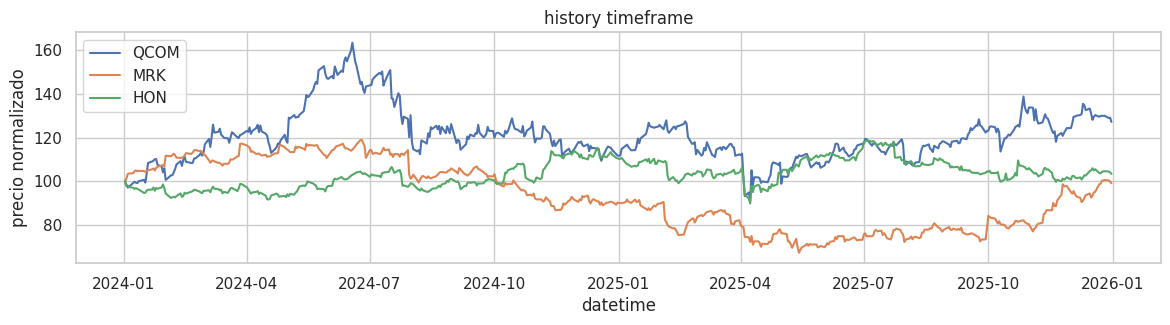

In [ ]:
# Respuesta # 1
# al estar normalizados los activos inician en el mismo instante al mismo %, al ser % la variacion es relativa lo que elimina el error de analisis por valores absolutos
# es la forma correcta de comparar si tengo la medida de analisis para todos los activos en el mismo intervalo de tiempo y partiendo del mismo lugar
# la diferencia en el comportamiento visual mientras los valores absolutos sin normalizar me permiten identificar precios absolutos al normalizar obtengo precios relativos
# relativos entre los 3 activos de analisis

from IPython.core.history import HistorySavingThread
from matplotlib import figure
# 1. Extraer los precios de cierre
close = precios['Close']
precio_normalizado = close/close.iloc[0] * 100
# 2. Graficar precios originales
fig, ax = plt.subplots(figsize=(14,3) )
for ticker in tickers:
  ax.plot(precio_normalizado.index, precio_normalizado[ticker], label=ticker )

ax.set_title('history timeframe')
ax.set_xlabel('datetime')
ax.set_ylabel('precio normalizado')
ax.legend()

plt.show()


# 3. Normalizar y graficar en base 100

## 🔄 Paso 3: Cálculo y Distribución de Rendimientos

1. Calcula los rendimientos diarios de los activos y elimina los valores nulos (`NaN`).
2. Genera un **histograma* para el activo que consideres que haya sido el más volátil.
3. Diseña un **Boxplot** comparativo que muestre los rendimientos diarios de tus 3 activos simultáneamente.

### 💬 Pregunta de interpretación #2:
Observando el Boxplot y el Histograma:
- ¿Qué activo presenta la mayor dispersión (caja más amplia o bigotes más largos) y qué te dice esto sobre su riesgo?
- ¿Identificas valores atípicos (outliers)? ¿Qué representan estos puntos en el contexto de la historia económica reciente de estas empresas?

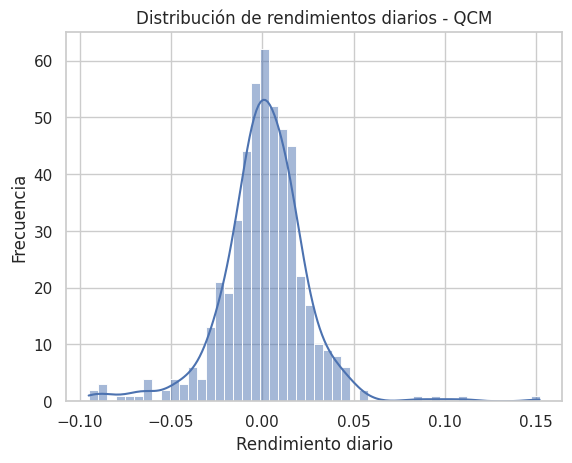

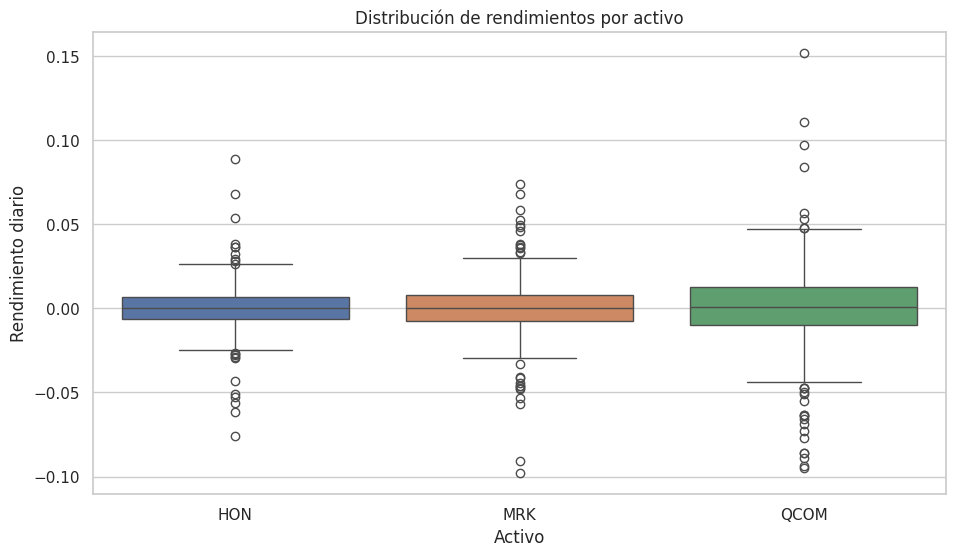

In [ ]:
# respuesta # 2
# QCOM es el activo mas riesgozo tiene mayor dispersion, su medida de insertidumbre es mayor, tiene mas riesgo que HON y MRK
# QCOM presenta el outlier mas disperso y significa que en su historia tuvo un movimiento muy lejos de su media en los rendimientos

# 1. Calcular rendimientos
rendimientos = close.pct_change()

# 2. Histograma con el activo más volátil
std_close = rendimientos.std()
std_close
#rendimiento = rendimientos['QCOM']
sns.histplot(
    data=rendimientos,
    x='QCOM',
    bins=50,
    kde= True
)

plt.title("Distribución de rendimientos diarios - QCM")
plt.xlabel("Rendimiento diario")
plt.ylabel("Frecuencia")
plt.show()


# 3. Boxplot comparativo de rendimientos

plt.figure(figsize=(11, 6))

sns.boxplot(data=rendimientos)

plt.title("Distribución de rendimientos por activo")
plt.xlabel("Activo")
plt.ylabel("Rendimiento diario")

plt.show()

## 📊 Paso 4: Asociación y Correlación

1. Calcula la matriz de correlación de Pearson para los rendimientos de tus 3 activos.
2. Grafica un **mapa de calor (Heatmap)**.

### 💬 Pregunta de interpretación #3:
- ¿Existe alguna correlación fuerte (cercana a 1 o -1) entre alguno de tus activos?
- Si tuvieras que armar un portafolio de inversión buscando la **diversificación** (minimizar el riesgo conjunto), ¿qué par de activos elegirías de acuerdo a tus resultados y por qué?

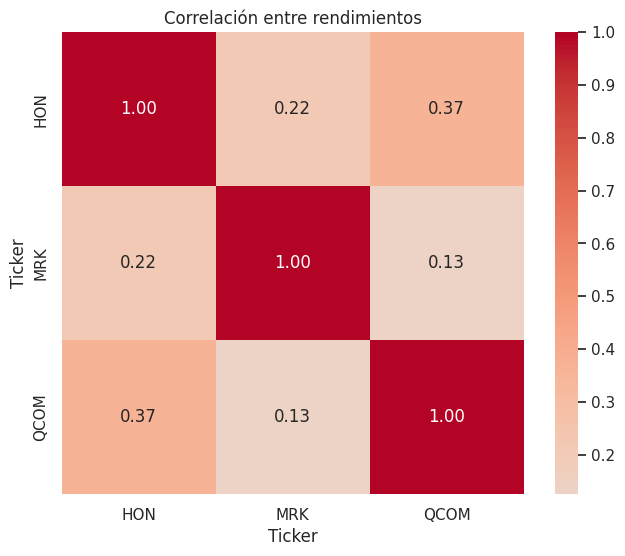

In [ ]:
# respuesta # 3
# No existe correlacion fuerte entre activos, la correlacion mas alta es 0.37
# QCOM y MRK presentan la correlacion mas baja pero no negativa, lo anterior minimiza el riesgo con esta informacio y en estas condiciones.

# 1. Calcular matriz de correlación
correlacion = rendimientos.corr()

correlacion

# 2. Dibujar el Heatmap utilizando Seaborn
plt.figure(figsize=(8, 6))

sns.heatmap(
    correlacion,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    square=True
)

plt.title("Correlación entre rendimientos")

plt.show()

## 🧮 Paso 5: Estadísticas Descriptivas y Conclusión

1. Genera un DataFrame de resumen estadístico que incluya para cada activo: Media, Mediana, Desviación Estándar, Mínimo y Máximo de los rendimientos diarios.
2. Escribe una breve conclusión final dirigida a un inversionista ficticio, interpretando los estadísticos clave obtenidos.

In [ ]:
# inversionista ficticio con perfil de 'alto riesgo'
# QCOM Y HON con la mayor correlacion y medias superiores, minimos superiores a MRK Y maximos superiores a MRK tiene mas oportunidad de retorno a mayor riesgo
# en una eventual COMPRA del los activos
#
# Generar resumen de estadísticas descriptivas (Media, Mediana, Desviación estándar, Mínimo y Máximo)
resumen = pd.DataFrame({
    "Media": rendimientos.mean(),
    "Mediana": rendimientos.median(),
    "Desviación estándar": rendimientos.std(),
    "Mínimo": rendimientos.min(),
    "Máximo": rendimientos.max()
})

resumen


,Media,Mediana,Desviación estándar,Mínimo,Máximo
Ticker,,,,,
HON,0.000159,0.000088,0.013617,-0.075914,0.088811
MRK,0.000116,0.000129,0.016381,-0.098059,0.073871
QCOM,0.000770,0.000879,0.024101,-0.095145,0.151853
